In [ ]:
!pip install ultralytics

In [ ]:
!mkdir -p /kaggle/working/yolo-dataset/valid/images
!mkdir -p /kaggle/working/yolo-dataset/valid/labels
!cp /kaggle/input/datasets/ahmedshayan1/yolo-dataset/train/images/* /kaggle/working/yolo-dataset/valid/images/
!cp /kaggle/input/datasets/ahmedshayan1/yolo-dataset/train/labels/* /kaggle/working/yolo-dataset/valid/labels/

In [ ]:
!yolo train \
    data=/kaggle/input/datasets/ahmedshayan1/yolo-dataset/data.yaml \
    model=yolo26s.pt \
    epochs=100 \
    imgsz=640 \
    batch=16 \
    device=0 \
    project=/kaggle/working/runs/detect \
    name=train2 \
    plots=True

In [ ]:
from ultralytics import YOLO

# Load a model
model = YOLO("yolo26n.yaml")  # build a new model from YAML
model = YOLO("yolo26n.pt")  # load a pretrained model (recommended for training)
model = YOLO("yolo26n.yaml").load("yolo26n.pt")  # build from YAML and transfer weights

# Train the model
results = model.train(data="coco8.yaml", epochs=100, imgsz=640)

In [ ]:
import os
import shutil
from glob import glob

# Paths
src_dir = "/kaggle/input/datasets/ahmedshayan1/yolo-dataset"
dst_dir = "/kaggle/working/yolo-dataset"

# Copy entire train folder
shutil.copytree(os.path.join(src_dir, "train"), os.path.join(dst_dir, "train"))

In [ ]:
import random

train_images = glob(os.path.join(dst_dir, "train/images", "*.jpg"))
random.seed(42)
val_size = int(0.2 * len(train_images))  # 20% for validation
val_images = random.sample(train_images, val_size)

# Create folders
os.makedirs(os.path.join(dst_dir, "valid/images"), exist_ok=True)
os.makedirs(os.path.join(dst_dir, "valid/labels"), exist_ok=True)

# Move validation images and labels
for img_path in val_images:
    base = os.path.basename(img_path)
    label_path = os.path.join(dst_dir, "train/labels", base.replace(".jpg", ".txt"))
    
    # Move image
    shutil.move(img_path, os.path.join(dst_dir, "valid/images", base))
    # Move corresponding label
    shutil.move(label_path, os.path.join(dst_dir, "valid/labels", base.replace(".jpg", ".txt")))

In [ ]:
data_yaml = f"""
train: {dst_dir}/train/images
val: {dst_dir}/valid/images
nc: 3
names: ['Kidney', 'Liver', 'Spleen']
"""

with open(os.path.join(dst_dir, "data.yaml"), "w") as f:
    f.write(data_yaml)

In [ ]:
!pip uninstall -y torch torchvision torchaudio
!pip install -U --no-cache-dir torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu126

In [3]:
!yolo train \
    data=/kaggle/working/yolo-dataset/data.yaml \
    model=yolo26s.pt \
    epochs=100 \
    imgsz=640 \
    batch=16 \
    device=0 \
    project=/kaggle/working/runs/detect \
    name=train_yolo26 \
    plots=True \
    save=True \
    task=detect

Ultralytics 8.4.36 🚀 Python-3.12.12 torch-2.11.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo-dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_yolo264, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True


image 1/1 /kaggle/input/datasets/imtkaggleteam/kidney-stone-classification-and-object-detection/stone/Stone_1131.JPG: 640x640 (no detections), 9.9ms
Speed: 2.3ms preprocess, 9.9ms inference, 0.3ms postprocess per image at shape (1, 3, 640, 640)
ultralytics.engine.results.Boxes object with attributes:

cls: tensor([], device='cuda:0')
conf: tensor([], device='cuda:0')
data: tensor([], device='cuda:0', size=(0, 6))
id: None
is_track: False
orig_shape: (512, 512)
shape: torch.Size([0, 6])
xywh: tensor([], device='cuda:0', size=(0, 4))
xywhn: tensor([], device='cuda:0', size=(0, 4))
xyxy: tensor([], device='cuda:0', size=(0, 4))
xyxyn: tensor([], device='cuda:0', size=(0, 4))
None


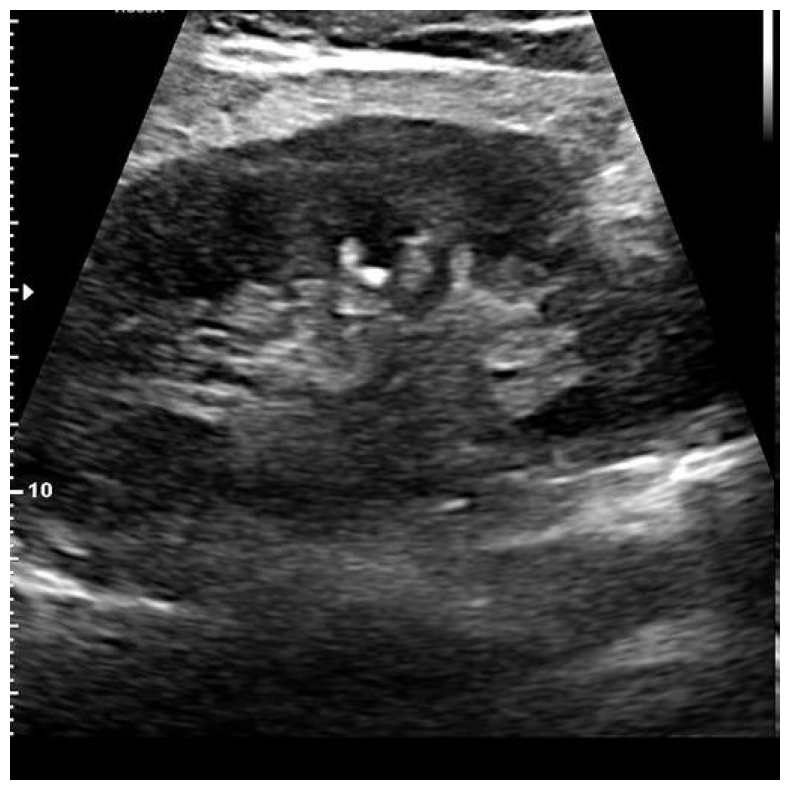

In [22]:
from ultralytics import YOLO
import cv2
from matplotlib import pyplot as plt

# Load your trained YOLO26 model
model = YOLO("/kaggle/working/runs/detect/train_yolo264/weights/best.pt")

# Path to your test image
img_path = "/kaggle/input/datasets/imtkaggleteam/kidney-stone-classification-and-object-detection/stone/Stone_1131.JPG"  # replace with your image path

# Run prediction
results = model.predict(source=img_path, imgsz=640, conf=0.25)  # conf=0.25 filters weak predictions

# results[0] contains detection info
print(results[0].boxes)   # bounding boxes and confidence
print(results[0].probs)   # class probabilities

# Optional: show image with predictions using OpenCV or matplotlib
# Convert BGR to RGB for matplotlib
img = cv2.imread(img_path)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Draw boxes using YOLO's built-in plot function
result_img = results[0].plot()  # returns an image with boxes drawn

plt.figure(figsize=(10, 10))
plt.imshow(result_img)
plt.axis('off')
plt.show()

In [9]:
print("hellow")

hellow
